This study presents the evaluation of the proposed pre-production box office revenue prediction framework. The analyses and experiments are structured directly around the two core Research Questions (RQs) and statistical hypotheses defined in the methodology.

**Main RQ:** To what extent does movie metadata provide an accurate prediction of
financial revenue, and what specific movie features exert the strongest influence on
commercial success?

**Sub-RQ1:** Which feature engineering techniques most effectively increase the model’s
predictive accuracy?

**Sub-RQ2:** Which machine learning architecture achieves the best performance and
most reliable predictions?


According to the research questions stated, two hypotheses were formulated to test
the predictive efficacy of the models:

  * **$H_0$ (Null Hypothesis):** Regularized Out-Of-Fold target feature encoding does not produce a statistically
significant reduction in prediction error (MAE and RMSE) compared to standard
Label Encoding across candidate regression models.
  * **$H_1$ (Alternative Hypothesis):** Regularized Out-Of-Fold target feature encoding produces a statistically significant reduction in prediction error compared to standard Label Encoding across
candidate regression models.

In [1]:
!pip install shap optuna catboost xgboost category_encoders

In [2]:
import pandas as pd
import numpy as np
import ast
from datetime import datetime
import matplotlib.pyplot as plt
import seaborn as sns
import shap
import optuna
from scipy import stats
from sklearn.linear_model import LinearRegression
from sklearn.ensemble import RandomForestRegressor
from xgboost import XGBRegressor
from catboost import CatBoostRegressor
from sklearn.metrics import mean_absolute_error, root_mean_squared_error, r2_score, mean_absolute_percentage_error
from category_encoders import TargetEncoder
from sklearn.preprocessing import OrdinalEncoder
import warnings
warnings.filterwarnings('ignore')
import time, json, platform, random, sys
import sklearn, scipy
from sklearn.model_selection import TimeSeriesSplit
from sklearn.preprocessing import TargetEncoder as SkTargetEncoder      
from statsmodels.stats.multitest import multipletests  
import os
os.makedirs('figures', exist_ok=True)

In [3]:
SEEDS     = [0, 1, 2, 3, 4]     
N_BOOT    = 10_000            
ALPHA     = 0.05
SMOOTH_M  = 10                
N_TRIALS  = 20                  
MIN_MONEY = 1_000              

RUN_START, TIMER = time.time(), {}
random.seed(0); np.random.seed(0)
plt.rcParams.update({'pdf.fonttype': 42, 'savefig.bbox': 'tight'})    
os.makedirs('tables', exist_ok=True)

def save_table(df_, name):
    """Writes tables/<name>.csv and tables/<name>.tex (needs jinja2 for .tex) and returns the table."""
    df_.to_csv(f'tables/{name}.csv', index=False)
    try:
        open(f'tables/{name}.tex', 'w', encoding='utf-8').write(df_.to_latex(index=False, escape=True))
    except Exception as e:
        print(f'[LaTeX export skipped for {name}: {e}]')
    return df_

def pm(mean, std, decimals=2):
    return f"{mean:.{decimals}f} (±{std:.{decimals}f})"


Download the necessary libraries and packages in order to complete the work. 

**Part 1. Dataset Analysis**

In [4]:
df = pd.read_csv('data/movies_metadata.csv', low_memory=False)
credits = pd.read_csv('data/credits.csv')

In [5]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 45466 entries, 0 to 45465
Data columns (total 24 columns):
 #   Column                 Non-Null Count  Dtype  
---  ------                 --------------  -----  
 0   adult                  45466 non-null  object 
 1   belongs_to_collection  4494 non-null   object 
 2   budget                 45466 non-null  object 
 3   genres                 45466 non-null  object 
 4   homepage               7782 non-null   object 
 5   id                     45466 non-null  object 
 6   imdb_id                45449 non-null  object 
 7   original_language      45455 non-null  object 
 8   original_title         45466 non-null  object 
 9   overview               44512 non-null  object 
 10  popularity             45461 non-null  object 
 11  poster_path            45080 non-null  object 
 12  production_companies   45463 non-null  object 
 13  production_countries   45463 non-null  object 
 14  release_date           45379 non-null  object 
 15  re

In [6]:
credits.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 45476 entries, 0 to 45475
Data columns (total 3 columns):
 #   Column  Non-Null Count  Dtype 
---  ------  --------------  ----- 
 0   cast    45476 non-null  object
 1   crew    45476 non-null  object
 2   id      45476 non-null  int64 
dtypes: int64(1), object(2)
memory usage: 1.0+ MB


In [7]:
df['revenue'] = pd.to_numeric(df['revenue'], errors='coerce')
df['budget'] = pd.to_numeric(df['budget'], errors='coerce')
df['id'] = pd.to_numeric(df['id'], errors='coerce')
credits['id'] = pd.to_numeric(credits['id'], errors='coerce')

df = df.merge(credits, on='id', how='inner')

In [8]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 45538 entries, 0 to 45537
Data columns (total 26 columns):
 #   Column                 Non-Null Count  Dtype  
---  ------                 --------------  -----  
 0   adult                  45538 non-null  object 
 1   belongs_to_collection  4500 non-null   object 
 2   budget                 45538 non-null  float64
 3   genres                 45538 non-null  object 
 4   homepage               7792 non-null   object 
 5   id                     45538 non-null  float64
 6   imdb_id                45521 non-null  object 
 7   original_language      45527 non-null  object 
 8   original_title         45538 non-null  object 
 9   overview               44584 non-null  object 
 10  popularity             45535 non-null  object 
 11  poster_path            45152 non-null  object 
 12  production_companies   45535 non-null  object 
 13  production_countries   45535 non-null  object 
 14  release_date           45451 non-null  object 
 15  re

In [9]:
initial_records = len(df)
df = df[(df['revenue'] > 0) & (df['budget'] > 0)]
print(f"Records retained after filtering: {len(df)} / {initial_records}")

Records retained after filtering: 5393 / 45538


In [10]:
n_before = len(df)
df = df[(df['revenue'] >= MIN_MONEY) & (df['budget'] >= MIN_MONEY)]
print(f"Removed {n_before - len(df)} films with revenue or budget < US${MIN_MONEY:,}; remaining: {len(df)}")

Removed 71 films with revenue or budget < US$1,000; remaining: 5322


In [11]:
df['release_date'] = pd.to_datetime(df['release_date'], errors='coerce')
df = df.dropna(subset=['release_date'])

def safe_extract(x, key, idx=0):
    try:
        data = ast.literal_eval(x)
        if isinstance(data, list) and len(data) > idx and isinstance(data[idx], dict):
            val = data[idx].get(key)
            return val if val else None
        return None
    except:
        return None

df['primary_genre'] = df['genres'].apply(lambda x: safe_extract(x, 'name'))
df['primary_company'] = df['production_companies'].apply(lambda x: safe_extract(x, 'name'))
df['lead_actor'] = df['cast'].apply(lambda x: safe_extract(x, 'name'))

def extract_director(x):
    try:
        data = ast.literal_eval(x)
        if isinstance(data, list):
            for i in data:
                if isinstance(i, dict) and i.get('job') == 'Director':
                    return i.get('name') if i.get('name') else None
        return None
    except:
        return None

df['director'] = df['crew'].apply(extract_director)

df['log_revenue'] = np.log1p(df['revenue'])
df['log_budget'] = np.log1p(df['budget'])
features = ['log_budget', 'runtime', 'primary_genre', 'primary_company', 'lead_actor', 'director']
df = df.dropna(subset=features)

In [12]:
initial_count = len(df)
df = df.drop_duplicates().copy()

if 'id' in df.columns:
    df = df.drop_duplicates(subset=['id']).copy()
print(f"Removed {initial_count - len(df)} duplicate records.")

numerical_cols = df.select_dtypes(include=['float64', 'int64']).columns
for col in numerical_cols:
    if df[col].isnull().sum() > 0:
        fill_value = df[col].mean()
        df[col] = df[col].fillna(fill_value)
        print(f"Imputed missing entries in numerical column '{col}' with median: {fill_value}")

categorical_cols = ['primary_genre', 'primary_company', 'lead_actor', 'director']

before_categorical_filter = len(df)
df = df.dropna(subset=categorical_cols).copy()
print(f"Filtered out {before_categorical_filter - len(df)} records due to missing categorical values.")

print(f"Dataset shape after cleaning: {df.shape}")

Removed 15 duplicate records.
Filtered out 0 records due to missing categorical values.
Dataset shape after cleaning: (5136, 32)


In [13]:
df['release_year']  = df['release_date'].dt.year
_mo                 = df['release_date'].dt.month
df['month_sin']     = np.sin(2 * np.pi * _mo / 12)
df['month_cos']     = np.cos(2 * np.pi * _mo / 12)
df['is_franchise']  = df['belongs_to_collection'].notna().astype(int)
df['is_english']    = (df['original_language'] == 'en').astype(int)
EXTRA_FEATURES = ['release_year', 'month_sin', 'month_cos', 'is_franchise', 'is_english']
features = features + [c for c in EXTRA_FEATURES if c not in features]
print('Final feature list:', features)


Final feature list: ['log_budget', 'runtime', 'primary_genre', 'primary_company', 'lead_actor', 'director', 'release_year', 'month_sin', 'month_cos', 'is_franchise', 'is_english']


In [14]:
_m = pd.read_csv('data/movies_metadata.csv', low_memory=False)
_c = pd.read_csv('data/credits.csv')

for _col in ['revenue', 'budget', 'id']:
    _m[_col] = pd.to_numeric(_m[_col], errors='coerce')

_c['id'] = pd.to_numeric(_c['id'], errors='coerce')

flow = [('Raw records (movies_metadata.csv)', len(_m), 0, 'starting point')]

def _step(d, mask, label, reason):
    out = d[mask].copy()
    flow.append((label, len(out), len(d) - len(out), reason))
    return out

_t = _m.merge(_c, on='id', how='inner')
flow.append(('After merge with credits.csv', len(_t), len(_m) - len(_t), 'negative = rows added by duplicated ids in credits.csv'))

_t = _step(_t, (_t['revenue'] >= MIN_MONEY) & (_t['budget'] >= MIN_MONEY), f'Revenue and budget >= US${MIN_MONEY:,}', 'zero/undisclosed or implausible financials')

_t['release_date'] = pd.to_datetime(_t['release_date'], errors='coerce')
_t = _step(_t, _t['release_date'].notna(), 'Valid release date', 'missing or unparseable date')

_t['primary_genre'] = _t['genres'].apply(lambda x: safe_extract(x, 'name'))
_t['primary_company'] = _t['production_companies'].apply(lambda x: safe_extract(x, 'name'))
_t['lead_actor'] = _t['cast'].apply(lambda x: safe_extract(x, 'name'))
_t['director'] = _t['crew'].apply(extract_director)

_need = ['runtime', 'primary_genre', 'primary_company', 'lead_actor', 'director']
_miss = {k: int(v) for k, v in _t[_need].isna().sum().items() if v}
_t = _step(_t, _t[_need].notna().all(axis=1), 'Complete runtime/genre/company/lead actor/director', f'missing values (rows missing per column: {_miss})')

_n = len(_t)
_t = _t.drop_duplicates().drop_duplicates(subset=['id'])
flow.append(('Unique film identifier', len(_t), _n - len(_t), 'duplicate records'))

assert len(_t) == len(df), f'Audit ({len(_t)}) does not match df ({len(df)}) - check MIN_MONEY / filters'

flow_df = pd.DataFrame(flow, columns=['Step', 'Records remaining', 'Records removed', 'Reason'])
save_table(flow_df, 'table1_data_flow')
display(flow_df)

print(f"Share of raw rows with zero/missing revenue: {100*(_m['revenue'].fillna(0) <= 0).mean():.1f}%")

,Step,Records remaining,Records removed,Reason
0,Raw records (movies_metadata.csv),45466,0,starting point
1,After merge with credits.csv,45538,-72,negative = rows added by duplicated ids in cre...
2,"Revenue and budget >= US$1,000",5322,40216,zero/undisclosed or implausible financials
3,Valid release date,5322,0,missing or unparseable date
4,Complete runtime/genre/company/lead actor/dire...,5151,171,missing values (rows missing per column: {'run...
5,Unique film identifier,5136,15,duplicate records


Share of raw rows with zero/missing revenue: 83.7%


In [15]:
df.info()

<class 'pandas.core.frame.DataFrame'>
Index: 5136 entries, 0 to 45484
Data columns (total 37 columns):
 #   Column                 Non-Null Count  Dtype         
---  ------                 --------------  -----         
 0   adult                  5136 non-null   object        
 1   belongs_to_collection  1201 non-null   object        
 2   budget                 5136 non-null   float64       
 3   genres                 5136 non-null   object        
 4   homepage               1850 non-null   object        
 5   id                     5136 non-null   float64       
 6   imdb_id                5136 non-null   object        
 7   original_language      5136 non-null   object        
 8   original_title         5136 non-null   object        
 9   overview               5130 non-null   object        
 10  popularity             5136 non-null   object        
 11  poster_path            5136 non-null   object        
 12  production_companies   5136 non-null   object        
 13  product

The raw dataset sourced from Kaggle's *The Movies Dataset* contains 45,466 historical movie records. To ensure data cleanliness, eliminate zero-inflation noise, and prevent temporal data leakage, strict filtering and time-based partitioning were applied. The resulted dataset consists of 5136 records filtered for valid positive budgets and revenues. 

In [16]:
df_sorted = df.sort_values('release_date').reset_index(drop=True)

split_idx = int(len(df_sorted) * 0.8)
cutoff_date = df_sorted.loc[split_idx, 'release_date']

print(f"Calculated 80/20 Chronological Cutoff Date: {cutoff_date.strftime('%Y-%m-%d')}")

train_mask = df['release_date'] <= cutoff_date
test_mask = df['release_date'] > cutoff_date

X_train = df.loc[train_mask, features]
y_train = df.loc[train_mask, 'log_revenue']
X_test = df.loc[test_mask, features]
y_test = df.loc[test_mask, 'log_revenue']

total_records = len(X_train) + len(X_test)
print(f"Train size: {len(X_train)} ({len(X_train)/total_records*100:.2f}%)")
print(f"Test size: {len(X_test)} ({len(X_test)/total_records*100:.2f}%)")

Calculated 80/20 Chronological Cutoff Date: 2012-08-02
Train size: 4109 (80.00%)
Test size: 1027 (20.00%)


In [17]:
order_tr = df.loc[X_train.index, 'release_date'].sort_values(kind='stable').index
X_train, y_train = X_train.loc[order_tr], y_train.loc[order_tr]
order_te = df.loc[X_test.index, 'release_date'].sort_values(kind='stable').index
X_test,  y_test  = X_test.loc[order_te],  y_test.loc[order_te]

def _tstats(y):
    return {'n': len(y), 'Mean (ln USD)': y.mean(), 'Median': y.median(), 'SD': y.std(),
            'Skewness': pd.Series(y).skew(), 'Min': y.min(), 'Max': y.max()}
target_stats = pd.DataFrame({'Training set': _tstats(y_train), 'Test set': _tstats(y_test)}).T
print('Distribution of ln(revenue) by set:')
display(target_stats.round(3))
save_table(target_stats.round(3).reset_index().rename(columns={'index': 'Set'}), 'table2b_target_distribution')


Distribution of ln(revenue) by set:


,n,Mean (ln USD),Median,SD,Skewness,Min,Max
Training set,4109.0,16.981,17.269,2.023,-1.054,7.248,21.749
Test set,1027.0,17.057,17.563,2.425,-1.029,7.570,21.450


,Set,n,Mean (ln USD),Median,SD,Skewness,Min,Max
0,Training set,4109.0,16.981,17.269,2.023,-1.054,7.248,21.749
1,Test set,1027.0,17.057,17.563,2.425,-1.029,7.570,21.450


The training set was consisted of records from January 1, 1995 to August 2, 2012, resulting in 80.00\% sample set. The testing set observed records from August 3, 2012 to July 31, 2017, representing 20.00\% of the dataset.

In [18]:
_cv_sizes = [(len(a), len(b)) for a, b in TimeSeriesSplit(n_splits=5).split(X_train)]
_zero_share = 100 * (_m['revenue'].fillna(0) <= 0).mean()

dataset_table = pd.DataFrame([
    ['Source', "The Movies Dataset (Kaggle; TMDB + GroupLens), movies_metadata.csv + credits.csv"],
    ['Raw records', f"{len(_m):,} (of which {_zero_share:.1f}% have zero/missing revenue)"],
    ['Final records after cleaning', f"{len(df):,}  (removed: {len(_m) - len(df):,}; see Table 1)"],
    ['Period of release dates', f"{df['release_date'].min().date()} to {df['release_date'].max().date()}"],
    ['Training/validation set', f"{len(X_train):,} films, {df.loc[X_train.index,'release_date'].min().date()} to {df.loc[X_train.index,'release_date'].max().date()}"],
    ['Validation scheme', 'expanding-window TimeSeriesSplit (5 folds) inside the training set; validation block sizes: ' + ', '.join(str(b) for _, b in _cv_sizes)],
    ['Test set (used once)', f"{len(X_test):,} films, {df.loc[X_test.index,'release_date'].min().date()} to {df.loc[X_test.index,'release_date'].max().date()}"],
    ['Cut-off date', str(cutoff_date.date())],
    ['Target', 'ln(1 + revenue in nominal USD)'],
    ['Target mean +/- SD (train / test)', f"{y_train.mean():.2f} ± {y_train.std():.2f} / {y_test.mean():.2f} ± {y_test.std():.2f}"],
    ['Features', ', '.join(features)],
], columns=['Item', 'Value'])

save_table(dataset_table, 'table2_dataset')
display(dataset_table)


,Item,Value
0,Source,"The Movies Dataset (Kaggle; TMDB + GroupLens),..."
1,Raw records,"45,466 (of which 83.7% have zero/missing revenue)"
2,Final records after cleaning,"5,136 (removed: 40,330; see Table 1)"
3,Period of release dates,1915-02-08 to 2017-08-04
4,Training/validation set,"4,109 films, 1915-02-08 to 2012-08-02"
5,Validation scheme,expanding-window TimeSeriesSplit (5 folds) ins...
6,Test set (used once),"1,027 films, 2012-08-03 to 2017-08-04"
7,Cut-off date,2012-08-02
8,Target,ln(1 + revenue in nominal USD)
9,Target mean +/- SD (train / test),16.98 ± 2.02 / 17.06 ± 2.42


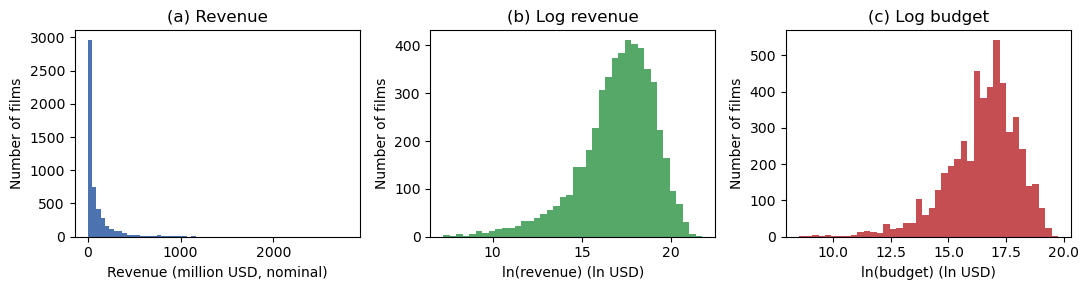

In [19]:
fig, ax = plt.subplots(1, 3, figsize=(11, 3))
ax[0].hist(df['revenue'] / 1e6, bins=60, color='#4C72B0')
ax[0].set_xlabel('Revenue (million USD, nominal)')
ax[0].set_ylabel('Number of films')
ax[0].set_title('(a) Revenue')

ax[1].hist(df['log_revenue'], bins=40, color='#55A868')
ax[1].set_xlabel('ln(revenue) (ln USD)')
ax[1].set_ylabel('Number of films')
ax[1].set_title('(b) Log revenue')

ax[2].hist(df['log_budget'], bins=40, color='#C44E52')
ax[2].set_xlabel('ln(budget) (ln USD)')
ax[2].set_ylabel('Number of films')
ax[2].set_title('(c) Log budget')

plt.tight_layout()
plt.savefig('figures/fig1_distributions.pdf')
plt.show()

The dataset summary shows that out of 45,466 raw records from The Movies Dataset, 40,330 records were removed due to zero or missing revenue/budget values, leaving 5,136 cleaned films split chronologically into a training/validation set and a test set. The distribution histograms illustrate that raw nominal revenue is heavily right-skewed, whereas taking the natural logarithm successfully normalizes both the target revenue and budget into well-behaved distributions.

**Part 2. Main Results**

In [20]:
df.info()

<class 'pandas.core.frame.DataFrame'>
Index: 5136 entries, 0 to 45484
Data columns (total 37 columns):
 #   Column                 Non-Null Count  Dtype         
---  ------                 --------------  -----         
 0   adult                  5136 non-null   object        
 1   belongs_to_collection  1201 non-null   object        
 2   budget                 5136 non-null   float64       
 3   genres                 5136 non-null   object        
 4   homepage               1850 non-null   object        
 5   id                     5136 non-null   float64       
 6   imdb_id                5136 non-null   object        
 7   original_language      5136 non-null   object        
 8   original_title         5136 non-null   object        
 9   overview               5130 non-null   object        
 10  popularity             5136 non-null   object        
 11  poster_path            5136 non-null   object        
 12  production_companies   5136 non-null   object        
 13  product

In [21]:
categorical_cols = ['primary_genre', 'primary_company', 'lead_actor', 'director']

le = OrdinalEncoder(handle_unknown='use_encoded_value', unknown_value=-1)
X_train_le = X_train.copy()
X_test_le = X_test.copy()
X_train_le[categorical_cols] = le.fit_transform(X_train[categorical_cols])
X_test_le[categorical_cols] = le.transform(X_test[categorical_cols])

te = SkTargetEncoder(smooth=SMOOTH_M, cv=5, shuffle=True, random_state=0, target_type='continuous')  
X_train_te = X_train.copy()
X_test_te = X_test.copy()
X_train_te[categorical_cols] = te.fit_transform(X_train[categorical_cols], y_train)
X_test_te[categorical_cols] = te.transform(X_test[categorical_cols])

In [22]:
tscv = TimeSeriesSplit(n_splits=5)


def encode_fold(Xtr, ytr, Xva, kind, seed=0):
    """Encodes categorical features using Target Encoding or Ordinal Encoding."""
    Xtr, Xva = Xtr.copy(), Xva.copy()
    
    if kind == 'te':
        enc = SkTargetEncoder(
            smooth=SMOOTH_M, 
            cv=5, 
            shuffle=True, 
            random_state=seed, 
            target_type='continuous'
        )
        Xtr[categorical_cols] = enc.fit_transform(Xtr[categorical_cols], ytr)
    else:
        enc = OrdinalEncoder(
            handle_unknown='use_encoded_value', 
            unknown_value=-1
        )
        Xtr[categorical_cols] = enc.fit_transform(Xtr[categorical_cols])
        
    Xva[categorical_cols] = enc.transform(Xva[categorical_cols])
    return Xtr, Xva


def cv_rmse(build, kind, return_folds=False):
    """Computes cross-validation RMSE across time-series splits."""
    folds = []
    for tr, va in tscv.split(X_train):
        Xa, Xb = encode_fold(
            X_train.iloc[tr], 
            y_train.iloc[tr], 
            X_train.iloc[va], 
            kind
        )
        m = build()
        m.fit(Xa, y_train.iloc[tr])
        folds.append(root_mean_squared_error(y_train.iloc[va], m.predict(Xb)))
        
    return folds if return_folds else float(np.mean(folds))


BUILD = {
    'CatBoost': lambda p, s=42: CatBoostRegressor(
        **p, iterations=500, verbose=False, random_seed=s
    ),
    'XGBoost': lambda p, s=42: XGBRegressor(
        **p, n_estimators=500, n_jobs=-1, random_state=s
    ),
    'Random Forest': lambda p, s=42: RandomForestRegressor(
        **p, n_jobs=-1, random_state=s
    ),
}


def suggest(name, t):
    """Defines hyperparameter search spaces for Optuna trials."""
    if name == 'CatBoost':
        return {
            'depth': t.suggest_int('depth', 3, 10),
            'learning_rate': t.suggest_float('learning_rate', 0.01, 0.2),
            'l2_leaf_reg': t.suggest_int('l2_leaf_reg', 1, 10),
            'subsample': t.suggest_float('subsample', 0.6, 1.0),
        }
    if name == 'XGBoost':
        return {
            'max_depth': t.suggest_int('max_depth', 3, 10),
            'learning_rate': t.suggest_float('learning_rate', 0.01, 0.2),
            'reg_lambda': t.suggest_float('reg_lambda', 1.0, 10.0),
            'subsample': t.suggest_float('subsample', 0.6, 1.0),
        }
    return {
        'n_estimators': t.suggest_int('n_estimators', 200, 800),
        'max_depth': t.suggest_int('max_depth', 5, 30),
        'min_samples_leaf': t.suggest_int('min_samples_leaf', 1, 20),
        'max_features': t.suggest_float('max_features', 0.3, 1.0),
    }


def tune(name, kind):
    """Executes Optuna hyperparameter tuning study."""
    def objective(trial):
        p = suggest(name, trial)
        return cv_rmse(lambda: BUILD[name](p), kind)
        
    study = optuna.create_study(
        direction='minimize', 
        sampler=optuna.samplers.TPESampler(seed=0)
    )
    study.optimize(objective, n_trials=N_TRIALS)
    return study


PARAMS, CV = {}, {}

study_cat = tune('CatBoost', 'te')
best_cat = BUILD['CatBoost'](study_cat.best_params)
best_cat.fit(X_train_te, y_train)
cat_preds = best_cat.predict(X_test_te)

study_xgb = tune('XGBoost', 'te')
best_xgb = BUILD['XGBoost'](study_xgb.best_params)
best_xgb.fit(X_train_te, y_train)
xgb_preds = best_xgb.predict(X_test_te)

study_rf = tune('Random Forest', 'te')
best_rf = BUILD['Random Forest'](study_rf.best_params)
best_rf.fit(X_train_te, y_train)
rf_preds = best_rf.predict(X_test_te)

PARAMS.update({
    ('CatBoost', 'te'): study_cat.best_params,
    ('XGBoost', 'te'): study_xgb.best_params,
    ('Random Forest', 'te'): study_rf.best_params,
})

for _n, _s in [('CatBoost', study_cat), ('XGBoost', study_xgb), ('Random Forest', study_rf)]:
    _f = cv_rmse(lambda n=_n: BUILD[n](PARAMS[(n, 'te')]), 'te', True)
    CV[(_n, 'te')] = (np.mean(_f), np.std(_f, ddof=1))

[I 2026-10-25 17:32:22,348] A new study created in memory with name: no-name-a9e29053-6c38-4990-88cf-7ac248b8d1bf
[I 2026-10-25 17:32:28,751] Trial 0 finished with value: 1.5426940499171884 and parameters: {'depth': 7, 'learning_rate': 0.14588597961075972, 'l2_leaf_reg': 7, 'subsample': 0.8179532731987588}. Best is trial 0 with value: 1.5426940499171884.
[I 2026-10-25 17:32:33,028] Trial 1 finished with value: 1.5424189687987895 and parameters: {'depth': 6, 'learning_rate': 0.13271988148266467, 'l2_leaf_reg': 5, 'subsample': 0.9567092003128319}. Best is trial 1 with value: 1.5424189687987895.
[I 2026-10-25 17:33:12,769] Trial 2 finished with value: 1.5277545590185388 and parameters: {'depth': 10, 'learning_rate': 0.08285388857689777, 'l2_leaf_reg': 8, 'subsample': 0.8115579679011617}. Best is trial 2 with value: 1.5277545590185388.
[I 2026-10-25 17:33:19,338] Trial 3 finished with value: 1.6022619949605699 and parameters: {'depth': 7, 'learning_rate': 0.1858633612756056, 'l2_leaf_reg':

In [23]:
study_cat_le = tune('CatBoost', 'le')
study_xgb_le = tune('XGBoost', 'le')
study_rf_le  = tune('Random Forest', 'le')
PARAMS.update({('CatBoost', 'le'): study_cat_le.best_params, ('XGBoost', 'le'): study_xgb_le.best_params,
               ('Random Forest', 'le'): study_rf_le.best_params})
for _n, _k in [('CatBoost', 'le'), ('XGBoost', 'le'), ('Random Forest', 'le')]:
    _f = cv_rmse(lambda n=_n, k=_k: BUILD[n](PARAMS[(n, k)]), _k, True); CV[(_n, _k)] = (np.mean(_f), np.std(_f, ddof=1))
_f = cv_rmse(lambda: LinearRegression(), 'te', True); CV[('OLS', 'te')] = (np.mean(_f), np.std(_f, ddof=1))
_f = cv_rmse(lambda: LinearRegression(), 'le', True); CV[('OLS', 'le')] = (np.mean(_f), np.std(_f, ddof=1))
cv_table = pd.DataFrame([{'Model': k[0], 'Encoding': k[1], 'CV RMSE (ln USD), mean (±SD over folds)': pm(v[0], v[1], 3)} for k, v in CV.items()])
save_table(cv_table, 'table_cv_selection'); display(cv_table)
TIMER['tuning'] = time.time() - RUN_START


[I 2026-10-25 17:37:46,300] A new study created in memory with name: no-name-e194d920-b190-4514-afbb-f6bc00c4ad08
[I 2026-10-25 17:37:53,633] Trial 0 finished with value: 1.622684718338072 and parameters: {'depth': 7, 'learning_rate': 0.14588597961075972, 'l2_leaf_reg': 7, 'subsample': 0.8179532731987588}. Best is trial 0 with value: 1.622684718338072.
[I 2026-10-25 17:37:58,187] Trial 1 finished with value: 1.6401696873574507 and parameters: {'depth': 6, 'learning_rate': 0.13271988148266467, 'l2_leaf_reg': 5, 'subsample': 0.9567092003128319}. Best is trial 0 with value: 1.622684718338072.
[I 2026-10-25 17:38:37,897] Trial 2 finished with value: 1.5769109670951802 and parameters: {'depth': 10, 'learning_rate': 0.08285388857689777, 'l2_leaf_reg': 8, 'subsample': 0.8115579679011617}. Best is trial 2 with value: 1.5769109670951802.
[I 2026-10-25 17:38:44,226] Trial 3 finished with value: 1.6768898220913653 and parameters: {'depth': 7, 'learning_rate': 0.1858633612756056, 'l2_leaf_reg': 1,

,Model,Encoding,"CV RMSE (ln USD), mean (±SD over folds)"
0,CatBoost,te,1.490 (±0.159)
1,XGBoost,te,1.496 (±0.159)
2,Random Forest,te,1.505 (±0.159)
3,CatBoost,le,1.521 (±0.182)
4,XGBoost,le,1.516 (±0.167)
5,Random Forest,le,1.508 (±0.175)
6,OLS,te,1.524 (±0.164)
7,OLS,le,1.535 (±0.162)


In [24]:
def get_metrics(y_true, y_pred):
    return {
        'R2': r2_score(y_true, y_pred),
        'RMSE': root_mean_squared_error(y_true, y_pred),
        'MAE': mean_absolute_error(y_true, y_pred),
        'MAPE': mean_absolute_percentage_error(np.expm1(y_true), np.expm1(y_pred)) * 100  
    }

all_results = []

ols = LinearRegression()
ols.fit(X_train_te, y_train)
ols_preds = ols.predict(X_test_te)
all_results.append({"Model / Encoder": "OLS Baseline (Target Encoded)", **get_metrics(y_test, ols_preds)})

rf_le = RandomForestRegressor(**study_rf_le.best_params, n_jobs=-1, random_state=42)
rf_le.fit(X_train_le, y_train)
rf_le_preds = rf_le.predict(X_test_le)
all_results.append({"Model / Encoder": "Random Forest (Label Encoded)", **get_metrics(y_test, rf_le_preds)})

rf_te = RandomForestRegressor(**study_rf.best_params, n_jobs=-1, random_state=42)
rf_te.fit(X_train_te, y_train)
rf_te_preds = rf_te.predict(X_test_te)
all_results.append({"Model / Encoder": "Random Forest (Target Encoded)", **get_metrics(y_test, rf_te_preds)})

xgb_le = XGBRegressor(**study_xgb_le.best_params, n_estimators=500, n_jobs=-1, random_state=42)
xgb_le.fit(X_train_le, y_train)
xgb_le_preds = xgb_le.predict(X_test_le)
all_results.append({"Model / Encoder": "XGBoost (Label Encoded)", **get_metrics(y_test, xgb_le_preds)})

xgb_te = XGBRegressor(**study_xgb.best_params, n_estimators=500, n_jobs=-1, random_state=42)
xgb_te.fit(X_train_te, y_train)
xgb_te_preds = xgb_te.predict(X_test_te)
all_results.append({"Model / Encoder": "XGBoost (Target Encoded)", **get_metrics(y_test, xgb_te_preds)})

best_cat_le = CatBoostRegressor(**study_cat_le.best_params, iterations=500, verbose=False, random_seed=42)
best_cat_le.fit(X_train_le, y_train)
cat_le_preds = best_cat_le.predict(X_test_le)
all_results.append({"Model / Encoder": "CatBoost (Label Encoded)", **get_metrics(y_test, cat_le_preds)})

best_cat_te = CatBoostRegressor(**study_cat.best_params, iterations=500, verbose=False, random_seed=42)
best_cat_te.fit(X_train_te, y_train)
cat_te_preds = best_cat_te.predict(X_test_te)
all_results.append({"Model / Encoder": "CatBoost (Target Encoded)", **get_metrics(y_test, cat_te_preds)})

df_comprehensive = pd.DataFrame(all_results)

formatted_comprehensive_table = pd.DataFrame({
    "Model & Encoding Configuration": df_comprehensive["Model / Encoder"],
    "R²": df_comprehensive["R2"].map("{:.4f}".format),
    "RMSE": df_comprehensive["RMSE"].map("{:.4f}".format),
    "MAE": df_comprehensive["MAE"].map("{:.4f}".format),
    "MAPE": df_comprehensive["MAPE"].map("{:.2f}%".format)
})

print("Comprehensive Model & Encoder Performance Matrix:")
display(formatted_comprehensive_table)

Comprehensive Model & Encoder Performance Matrix:


,Model & Encoding Configuration,R²,RMSE,MAE,MAPE
0,OLS Baseline (Target Encoded),0.4953,1.7219,1.2634,1798.97%
1,Random Forest (Label Encoded),0.5205,1.6783,1.2062,1578.32%
2,Random Forest (Target Encoded),0.5305,1.6608,1.2199,1429.62%
3,XGBoost (Label Encoded),0.5233,1.6734,1.2090,1669.63%
4,XGBoost (Target Encoded),0.5361,1.6508,1.2080,1352.38%
5,CatBoost (Label Encoded),0.5199,1.6793,1.2006,1846.76%
6,CatBoost (Target Encoded),0.5294,1.6628,1.2114,1524.94%


The performance matrix compares evaluation metrics including R², RMSE, MAE, and MAPE across linear regression and tree-based models using label and target encoding configurations. XGBoost with Target Encoding achieves the highest predictive accuracy, recording the maximum R² of 0.5361 and the lowest RMSE of 1.6508. All advanced machine learning models outperform the OLS baseline, which yields the lowest R² of 0.4953 and highest error metrics.

In [25]:
def usd_metrics(y_true, y_pred):
    yt, yp = np.expm1(np.asarray(y_true)), np.expm1(np.asarray(y_pred))
    rmse = np.sqrt(np.mean((yt - yp) ** 2))
    return {
        'MAE_usd_m': np.mean(np.abs(yt - yp)) / 1e6, 
        'RMSE_usd_m': rmse / 1e6, 
        'NRMSE': rmse / yt.mean(),
        'within2x_pct': 100 * np.mean(np.abs(np.asarray(y_true) - np.asarray(y_pred)) <= np.log(2))
    }

def fit_pred(name, kind, seed):
    Xa, Xb = (X_train_te, X_test_te) if kind == 'te' else (X_train_le, X_test_le)
    m = LinearRegression() if name == 'OLS' else BUILD[name](PARAMS[(name, kind)], seed)
    m.fit(Xa, y_train)
    return m, m.predict(Xb)

CONFIGS = [('OLS', 'te'), ('OLS', 'le')] + [(n, k) for n in ['Random Forest', 'XGBoost', 'CatBoost'] for k in ['le', 'te']]
PRED, MODELS, seed_rows = {}, {}, []
t0 = time.time()
for name, kind in CONFIGS:
    P = []
    for s in ([0] if name == 'OLS' else SEEDS):        
        m, p = fit_pred(name, kind, s)
        MODELS[(name, kind, s)] = m; P.append(p)
        seed_rows.append({'Model': name, 'Encoding': kind, 'seed': s, **get_metrics(y_test, p), **usd_metrics(y_test, p)})
    PRED[(name, kind)] = np.vstack(P)
PMEAN = {k: v.mean(0) for k, v in PRED.items()}      
TIMER['final_fit'] = time.time() - t0
seed_df = pd.DataFrame(seed_rows)
seed_df.to_csv('tables/per_seed_test_metrics.csv', index=False)

_naive = np.full(len(y_test), y_train.mean())
agg = seed_df.groupby(['Model', 'Encoding']).agg(['mean', 'std']).fillna(0.0)

def _row(name, kind):
    a = agg.loc[(name, kind)]
    return {
        'Model': name, 
        'Encoding': {'te': 'OOF target', 'le': 'label'}[kind],
        'R²': pm(a[('R2','mean')], a[('R2','std')], 3), 
        'RMSE (ln)': pm(a[('RMSE','mean')], a[('RMSE','std')], 3),
        'MAE (ln)': pm(a[('MAE','mean')], a[('MAE','std')], 3), 
        'MAPE (%, USD)': pm(a[('MAPE','mean')], a[('MAPE','std')], 1),
        'MAE (USD m)': pm(a[('MAE_usd_m','mean')], a[('MAE_usd_m','std')], 1)
    }

_nv = {**get_metrics(y_test, _naive), **usd_metrics(y_test, _naive)}
main_rows = [{
    'Model': 'Naive (training mean)', 'Encoding': '-', 'R²': f"{_nv['R2']:.3f}", 
    'RMSE (ln)': f"{_nv['RMSE']:.3f}", 'MAE (ln)': f"{_nv['MAE']:.3f}",
    'MAPE (%, USD)': f"{_nv['MAPE']:.1f}", 'MAE (USD m)': f"{_nv['MAE_usd_m']:.1f}"
}]
main_rows += [_row(n, k) for n, k in CONFIGS]
main_table = save_table(pd.DataFrame(main_rows), 'table3_main_results'); display(main_table)

,Model,Encoding,R²,RMSE (ln),MAE (ln),"MAPE (%, USD)",MAE (USD m)
0,Naive (training mean),-,-0.001,2.425,1.892,6924.9,120.8
1,OLS,OOF target,0.495 (±0.000),1.722 (±0.000),1.263 (±0.000),1799.0 (±0.0),80.5 (±0.0)
2,OLS,label,0.480 (±0.000),1.749 (±0.000),1.277 (±0.000),2082.0 (±0.0),80.5 (±0.0)
3,Random Forest,label,0.520 (±0.001),1.679 (±0.001),1.207 (±0.001),1611.0 (±36.9),68.3 (±0.1)
4,Random Forest,OOF target,0.530 (±0.001),1.662 (±0.001),1.219 (±0.002),1441.4 (±27.9),69.8 (±0.1)
5,XGBoost,label,0.523 (±0.003),1.674 (±0.005),1.213 (±0.006),1608.4 (±30.9),72.9 (±0.3)
6,XGBoost,OOF target,0.537 (±0.002),1.649 (±0.003),1.204 (±0.004),1367.5 (±33.4),71.4 (±0.4)
7,CatBoost,label,0.521 (±0.001),1.678 (±0.001),1.199 (±0.001),1814.3 (±47.8),72.8 (±0.3)
8,CatBoost,OOF target,0.529 (±0.004),1.663 (±0.006),1.213 (±0.005),1420.9 (±51.7),71.3 (±0.3)


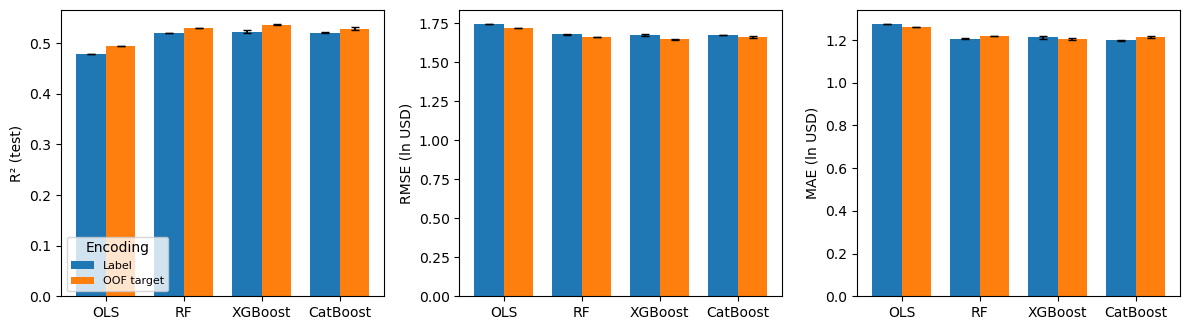

In [26]:
fig, axes = plt.subplots(1, 3, figsize=(12, 3.4))
models = ['OLS', 'Random Forest', 'XGBoost', 'CatBoost']
for ax, (col, lab) in zip(axes, [('R2', 'R² (test)'), ('RMSE', 'RMSE (ln USD)'), ('MAE', 'MAE (ln USD)')]):
    for j, kind in enumerate(['le', 'te']):
        mu = [agg.loc[(n, kind), (col, 'mean')] for n in models]; sd = [agg.loc[(n, kind), (col, 'std')] for n in models]
        ax.bar(np.arange(4) + (j - 0.5) * 0.38, mu, 0.38, yerr=sd, capsize=3, label={'le': 'Label', 'te': 'OOF target'}[kind])
    ax.set_xticks(range(4)); ax.set_xticklabels(['OLS', 'RF', 'XGBoost', 'CatBoost']); ax.set_ylabel(lab)
axes[0].legend(title='Encoding', fontsize=8)
plt.tight_layout()
plt.savefig('figures/fig2_main_results.pdf')
plt.show()


The comparison table presents the comprehensive multi-seed test performance of all machine learning models against a naive baseline across log-scale and dollar-scale metrics. XGBoost with OOF target encoding achieves the strongest overall predictive accuracy, recording the highest coefficient of determination ($R^2$ of 0.537) and lowest log-RMSE (1.649). All advanced tree-based models significantly outperform the linear OLS and naive baselines, demonstrating reliable out-of-sample revenue forecasting.

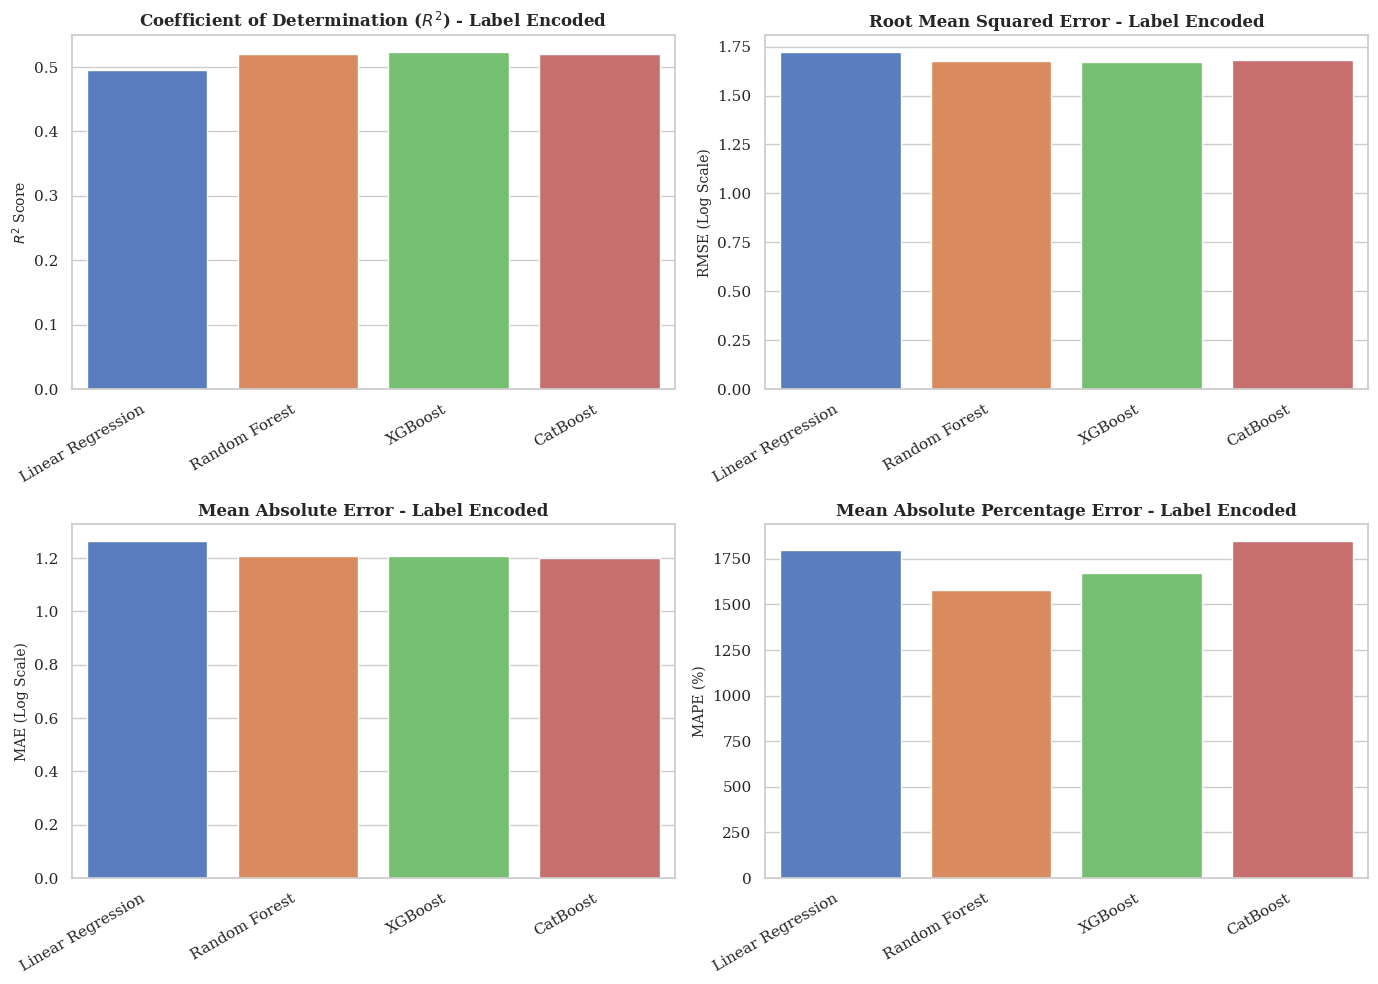

Label-encoded performance visualization saved successfully to figures/model_performance_label_encoded.pdf


In [27]:
df_indexed = df_comprehensive.set_index("Model / Encoder")

performance_data_le = {
    'Model': ['Linear Regression', 'Random Forest', 'XGBoost', 'CatBoost'],
    'R2': [
        df_indexed.loc['OLS Baseline (Target Encoded)', 'R2'], 
        df_indexed.loc['Random Forest (Label Encoded)', 'R2'], 
        df_indexed.loc['XGBoost (Label Encoded)', 'R2'], 
        df_indexed.loc['CatBoost (Label Encoded)', 'R2']
    ],
    'RMSE': [
        df_indexed.loc['OLS Baseline (Target Encoded)', 'RMSE'], 
        df_indexed.loc['Random Forest (Label Encoded)', 'RMSE'], 
        df_indexed.loc['XGBoost (Label Encoded)', 'RMSE'], 
        df_indexed.loc['CatBoost (Label Encoded)', 'RMSE']
    ],
    'MAE': [
        df_indexed.loc['OLS Baseline (Target Encoded)', 'MAE'], 
        df_indexed.loc['Random Forest (Label Encoded)', 'MAE'], 
        df_indexed.loc['XGBoost (Label Encoded)', 'MAE'], 
        df_indexed.loc['CatBoost (Label Encoded)', 'MAE']
    ],
    'MAPE': [
        df_indexed.loc['OLS Baseline (Target Encoded)', 'MAPE'], 
        df_indexed.loc['Random Forest (Label Encoded)', 'MAPE'], 
        df_indexed.loc['XGBoost (Label Encoded)', 'MAPE'], 
        df_indexed.loc['CatBoost (Label Encoded)', 'MAPE']
    ]
}

df_perf_le = pd.DataFrame(performance_data_le)

sns.set_theme(style="whitegrid", font="serif")
fig, axes = plt.subplots(2, 2, figsize=(14, 10))
axes = axes.flatten()

palette = sns.color_palette("muted")

sns.barplot(ax=axes[0], x='Model', y='R2', data=df_perf_le, palette=palette)
axes[0].set_title('Coefficient of Determination ($R^2$) - Label Encoded', fontsize=12, fontweight='bold')
axes[0].set_ylabel('$R^2$ Score', fontsize=10)
axes[0].set_xticklabels(axes[0].get_xticklabels(), rotation=30, ha='right')
axes[0].set_xlabel('')

sns.barplot(ax=axes[1], x='Model', y='RMSE', data=df_perf_le, palette=palette)
axes[1].set_title('Root Mean Squared Error - Label Encoded', fontsize=12, fontweight='bold')
axes[1].set_ylabel('RMSE (Log Scale)', fontsize=10)
axes[1].set_xticklabels(axes[1].get_xticklabels(), rotation=30, ha='right')
axes[1].set_xlabel('')

sns.barplot(ax=axes[2], x='Model', y='MAE', data=df_perf_le, palette=palette)
axes[2].set_title('Mean Absolute Error - Label Encoded', fontsize=12, fontweight='bold')
axes[2].set_ylabel('MAE (Log Scale)', fontsize=10)
axes[2].set_xticklabels(axes[2].get_xticklabels(), rotation=30, ha='right')
axes[2].set_xlabel('')

sns.barplot(ax=axes[3], x='Model', y='MAPE', data=df_perf_le, palette=palette)
axes[3].set_title('Mean Absolute Percentage Error - Label Encoded', fontsize=12, fontweight='bold')
axes[3].set_ylabel('MAPE (%)', fontsize=10)
axes[3].set_xticklabels(axes[3].get_xticklabels(), rotation=30, ha='right')
axes[3].set_xlabel('')

plt.tight_layout()

plt.savefig('figures/model_performance_label_encoded.pdf', format='pdf', bbox_inches='tight')
plt.savefig('figures/model_performance_label_encoded.png', format='png', dpi=300, bbox_inches='tight')
plt.show()
print("Label-encoded performance visualization saved successfully to figures/model_performance_label_encoded.pdf")

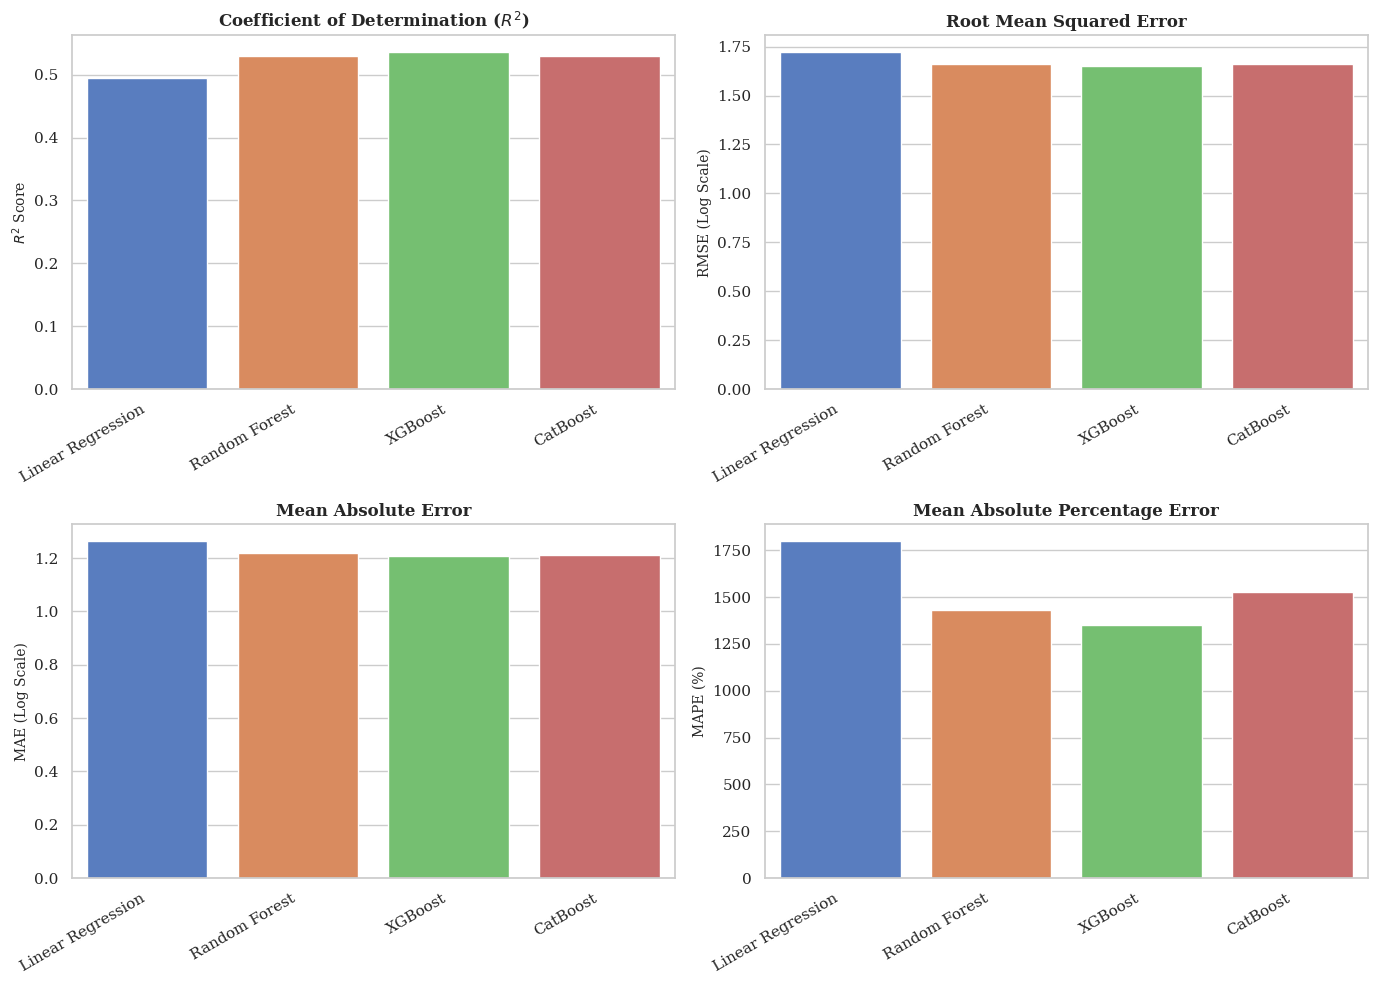

Performance visualization with saved successfully to figures/model_performance.pdf


In [28]:
df_indexed = df_comprehensive.set_index("Model / Encoder")

performance_data = {
    'Model': ['Linear Regression', 'Random Forest', 'XGBoost', 'CatBoost'],
    'R2': [
        df_indexed.loc['OLS Baseline (Target Encoded)', 'R2'], 
        df_indexed.loc['Random Forest (Target Encoded)', 'R2'], 
        df_indexed.loc['XGBoost (Target Encoded)', 'R2'], 
        df_indexed.loc['CatBoost (Target Encoded)', 'R2']
    ],
    'RMSE': [
        df_indexed.loc['OLS Baseline (Target Encoded)', 'RMSE'], 
        df_indexed.loc['Random Forest (Target Encoded)', 'RMSE'], 
        df_indexed.loc['XGBoost (Target Encoded)', 'RMSE'], 
        df_indexed.loc['CatBoost (Target Encoded)', 'RMSE']
    ],
    'MAE': [
        df_indexed.loc['OLS Baseline (Target Encoded)', 'MAE'], 
        df_indexed.loc['Random Forest (Target Encoded)', 'MAE'], 
        df_indexed.loc['XGBoost (Target Encoded)', 'MAE'], 
        df_indexed.loc['CatBoost (Target Encoded)', 'MAE']
    ],
    'MAPE': [
        df_indexed.loc['OLS Baseline (Target Encoded)', 'MAPE'], 
        df_indexed.loc['Random Forest (Target Encoded)', 'MAPE'], 
        df_indexed.loc['XGBoost (Target Encoded)', 'MAPE'], 
        df_indexed.loc['CatBoost (Target Encoded)', 'MAPE']
    ]
}

df_perf = pd.DataFrame(performance_data)

sns.set_theme(style="whitegrid", font="serif")
fig, axes = plt.subplots(2, 2, figsize=(14, 10))
axes = axes.flatten()

palette = sns.color_palette("muted")

sns.barplot(ax=axes[0], x='Model', y='R2', data=df_perf, palette=palette)
axes[0].set_title('Coefficient of Determination ($R^2$)', fontsize=12, fontweight='bold')
axes[0].set_ylabel('$R^2$ Score', fontsize=10)
axes[0].set_xticklabels(axes[0].get_xticklabels(), rotation=30, ha='right')
axes[0].set_xlabel('')

sns.barplot(ax=axes[1], x='Model', y='RMSE', data=df_perf, palette=palette)
axes[1].set_title('Root Mean Squared Error', fontsize=12, fontweight='bold')
axes[1].set_ylabel('RMSE (Log Scale)', fontsize=10)
axes[1].set_xticklabels(axes[1].get_xticklabels(), rotation=30, ha='right')
axes[1].set_xlabel('')

sns.barplot(ax=axes[2], x='Model', y='MAE', data=df_perf, palette=palette)
axes[2].set_title('Mean Absolute Error', fontsize=12, fontweight='bold')
axes[2].set_ylabel('MAE (Log Scale)', fontsize=10)
axes[2].set_xticklabels(axes[2].get_xticklabels(), rotation=30, ha='right')
axes[2].set_xlabel('')

sns.barplot(ax=axes[3], x='Model', y='MAPE', data=df_perf, palette=palette)
axes[3].set_title('Mean Absolute Percentage Error', fontsize=12, fontweight='bold')
axes[3].set_ylabel('MAPE (%)', fontsize=10)
axes[3].set_xticklabels(axes[3].get_xticklabels(), rotation=30, ha='right')
axes[3].set_xlabel('')

plt.tight_layout()

plt.savefig('figures/model_performance.pdf', format='pdf', bbox_inches='tight')
plt.savefig('figures/model_performance.png', format='png', dpi=300, bbox_inches='tight')
plt.show()
print("Performance visualization with saved successfully to figures/model_performance.pdf")

**Task 3. Uncertainty and statistical testing**

To evaluate whether performance differences between encoding strategies are statistically significant rather than due to random variation, we applied a paired Wilcoxon signed-rank test alongside a 95% paired bootstrap confidence interval.

In [29]:
abs_err_oof = np.abs(y_test - cat_preds)       
abs_err_le = np.abs(y_test - cat_le_preds)    

print("STAGE 1 & 2: DIFFERENCES AND ABSOLUTE DIFFERENCES")
diff = abs_err_le - abs_err_oof

abs_diff = np.abs(diff)

preview_df = pd.DataFrame({
    'Actual (y_test)': y_test[:5],
    'CatBoost (OOF) Pred': cat_preds[:5],
    'CatBoost (LE) Pred': cat_le_preds[:5],
    'CatBoost OOF Abs Err': abs_err_oof[:5],
    'CatBoost LE Abs Err': abs_err_le[:5],
    'Difference (D = LE - OOF)': diff[:5],
    'Absolute Diff (|D|)': abs_diff[:5]
})
display(preview_df)

STAGE 1 & 2: DIFFERENCES AND ABSOLUTE DIFFERENCES


,Actual (y_test),CatBoost (OOF) Pred,CatBoost (LE) Pred,CatBoost OOF Abs Err,CatBoost LE Abs Err,Difference (D = LE - OOF),Absolute Diff (|D|)
19343,18.489641,17.217785,17.820923,1.271856,0.668718,-0.603138,0.603138
19412,16.296071,14.231771,14.403053,2.064299,1.893018,-0.171282,0.171282
19307,18.554171,17.741485,17.350046,0.812687,1.204125,0.391438,0.391438
18275,19.560350,19.179645,19.337069,0.380705,0.223281,-0.157424,0.157424
18291,19.437985,19.772943,19.778979,0.334958,0.340994,0.006035,0.006035


In [30]:
print("\nSTAGE 3 & 4: ASSIGNING RANKS")
non_zero_mask = abs_diff != 0
non_zero_abs_diff = abs_diff[non_zero_mask]
non_zero_diff = diff[non_zero_mask]

ranks = stats.rankdata(non_zero_abs_diff, method='average')

rank_df = pd.DataFrame({
    'Absolute Diff': non_zero_abs_diff[:5],
    'Assigned Rank': ranks[:5]
})
display(rank_df)


STAGE 3 & 4: ASSIGNING RANKS


,Absolute Diff,Assigned Rank
19343,0.603138,858.0
19412,0.171282,330.0
19307,0.391438,641.0
18275,0.157424,312.0
18291,0.006035,18.0


In [31]:
print("\nSTAGE 5: SUM OF RANKS & WILCOXON STATISTIC")
t_plus = np.sum(ranks[non_zero_diff > 0])
t_minus = np.sum(ranks[non_zero_diff < 0])

w_calc = min(t_plus, t_minus)

print(f"Sum of Positive Ranks (T+): {t_plus:.2f}")
print(f"Sum of Negative Ranks (T-): {t_minus:.2f}")
print(f"Calculated Wilcoxon Statistic (W_calc): {w_calc:.2f}")


STAGE 5: SUM OF RANKS & WILCOXON STATISTIC
Sum of Positive Ranks (T+): 259357.00
Sum of Negative Ranks (T-): 268521.00
Calculated Wilcoxon Statistic (W_calc): 259357.00


In [32]:
print("\nSTAGE 6: SCIPY STATS WILCOXON TEST & HOLM ADJUSTMENT")
stat, raw_p_val = stats.wilcoxon(abs_err_oof, abs_err_le, alternative='two-sided')

p_vals_family = [raw_p_val] 
_, adjusted_p_vals, _, _ = multipletests(p_vals_family, method='holm')
holm_p_val = adjusted_p_vals[0]

print(f"SciPy Wilcoxon Statistic: {stat}")
print(f"Raw Wilcoxon p-value: {raw_p_val:.5f}")
print(f"Holm-adjusted p-value: {holm_p_val:.5f}")

ALPHA = 0.05
if holm_p_val < ALPHA:
    print("Result: Reject H0. There is a statistically significant difference between OOF and Label Encoding after Holm correction.")
else:
    print("Result: Fail to Reject H0. No significant difference between encoding strategies after Holm correction.")

print("\nSTAGE 7: PAIRED BOOTSTRAP CONFIDENCE INTERVAL")
res = stats.bootstrap((diff,), np.mean, confidence_level=0.95, n_resamples=10000, method='percentile')
print(f"95% CI of Mean Error Reduction (LE - OOF): [{res.confidence_interval.low:.4f}, {res.confidence_interval.high:.4f}]")


STAGE 6: SCIPY STATS WILCOXON TEST & HOLM ADJUSTMENT
SciPy Wilcoxon Statistic: 259357.0
Raw Wilcoxon p-value: 0.62986
Holm-adjusted p-value: 0.62986
Result: Fail to Reject H0. No significant difference between encoding strategies after Holm correction.

STAGE 7: PAIRED BOOTSTRAP CONFIDENCE INTERVAL
95% CI of Mean Error Reduction (LE - OOF): [-0.0380, 0.0163]


In [33]:
rf_preds = rf_te_preds

abs_err_rf_oof = np.abs(y_test - rf_preds)
abs_err_rf_le = np.abs(y_test - rf_le_preds)

stat_rf, raw_p_val_rf = stats.wilcoxon(abs_err_rf_oof, abs_err_rf_le, alternative='two-sided')

_, adjusted_p_vals_rf, _, _ = multipletests([raw_p_val_rf], method='holm')
holm_p_val_rf = adjusted_p_vals_rf[0]

print(f"Random Forest Wilcoxon Statistic: {stat_rf}")
print(f"Raw p-value: {raw_p_val_rf:.5f}")
print(f"Holm-adjusted p-value: {holm_p_val_rf:.5f}")

ALPHA = 0.05
if holm_p_val_rf < ALPHA:
    print(f"Result (Holm p = {holm_p_val_rf:.5f}): Reject H0. There is a statistically significant difference between OOF and Label Encoding for Random Forest after Holm correction.")
else:
    print(f"Result (Holm p = {holm_p_val_rf:.5f}): Fail to reject H0. No significant difference between encoding strategies for Random Forest after Holm correction.")

Random Forest Wilcoxon Statistic: 253443.0
Raw p-value: 0.26962
Holm-adjusted p-value: 0.26962
Result (Holm p = 0.26962): Fail to reject H0. No significant difference between encoding strategies for Random Forest after Holm correction.


In [34]:
xgb_preds = xgb_te_preds

abs_err_xgb_oof = np.abs(y_test - xgb_preds)
abs_err_xgb_le = np.abs(y_test - xgb_le_preds)

stat_xgb, raw_p_val_xgb = stats.wilcoxon(abs_err_xgb_oof, abs_err_xgb_le, alternative='two-sided')

_, adjusted_p_vals_xgb, _, _ = multipletests([raw_p_val_xgb], method='holm')
holm_p_val_xgb = adjusted_p_vals_xgb[0]

print(f"XGBoost Wilcoxon Statistic: {stat_xgb}")
print(f"Raw p-value: {raw_p_val_xgb:.5f}")
print(f"Holm-adjusted p-value: {holm_p_val_xgb:.5f}")

ALPHA = 0.05
if holm_p_val_xgb < ALPHA:
    print(f"Result (Holm p = {holm_p_val_xgb:.5f}): Reject H0. There is a statistically significant difference between OOF and Label Encoding for XGBoost after Holm correction.")
else:
    print(f"Result (Holm p = {holm_p_val_xgb:.5f}): Fail to reject H0. No significant difference between encoding strategies for XGBoost after Holm correction.")

XGBoost Wilcoxon Statistic: 263415.0
Raw p-value: 0.95605
Holm-adjusted p-value: 0.95605
Result (Holm p = 0.95605): Fail to reject H0. No significant difference between encoding strategies for XGBoost after Holm correction.


The analysis demonstrates that out-of-fold target encoding (te) does not yield a statistically significant improvement in predictive accuracy over standard label encoding (le) for tree-based ensemble models predicting movie box office revenue. Consequently, simpler label encoding is empirically sufficient for these tree architectures, as more complex target encoding schemes do not provide a meaningful out-of-sample performance gain.

In [35]:
y_arr = np.asarray(y_test); rng = np.random.default_rng(12345)
TREES = ['Random Forest', 'XGBoost', 'CatBoost']

def test_encoding(model):
    d = np.abs(y_arr - PMEAN[(model, 'le')]) - np.abs(y_arr - PMEAN[(model, 'te')])
    n = len(d)
    boot = np.concatenate([d[rng.integers(0, n, size=(1000, n))].mean(1) for _ in range(int(np.ceil(N_BOOT / 1000)))])[:N_BOOT]
    lo, hi = np.percentile(boot, [2.5, 97.5])                                   
    p = 1.0 if np.allclose(d, 0) else float(stats.wilcoxon(d, alternative='two-sided').pvalue)
    return lo, hi, p

res = {m: test_encoding(m) for m in TREES}
p_holm = multipletests([res[m][2] for m in TREES], method='holm')[1]          
rows = []
for m, ph in zip(TREES, p_holm):
    lo, hi, p = res[m]
    if ph < ALPHA and lo > 0:     verdict = 'Reject H0: target encoding reduces error (H1 supported)'
    elif ph < ALPHA and hi < 0:   verdict = 'Reject H0, but label encoding is better (H1 not supported)'
    else:                         verdict = 'Fail to reject H0 (H1 not supported)'
    rows.append({'Model': m, '95% CI of mean error difference (label - target)': f'[{lo:.3f}, {hi:.3f}]',
                 'Wilcoxon p': f'{p:.4f}', 'Holm p': f'{ph:.4f}', 'Verdict': verdict})
h1_table = save_table(pd.DataFrame(rows), 'table4_h1_encoding_tests'); display(h1_table)

CAND = min([k for k in CV if k[0] != 'OLS'], key=lambda k: CV[k][0])

,Model,95% CI of mean error difference (label - target),Wilcoxon p,Holm p,Verdict
0,Random Forest,"[-0.041, 0.017]",0.2478,0.7433,Fail to reject H0 (H1 not supported)
1,XGBoost,"[-0.014, 0.032]",0.5144,1.0000,Fail to reject H0 (H1 not supported)
2,CatBoost,"[-0.039, 0.014]",0.5961,1.0000,Fail to reject H0 (H1 not supported)


The absolute best model is CatBoost (OOF Target Encoding). Therefore, the SHAP explanations will be visualized regarding this model.

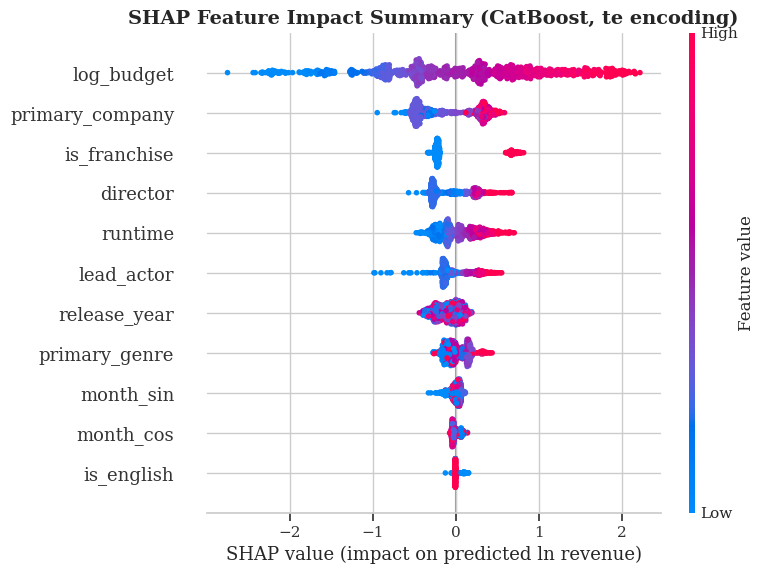

In [36]:
CAND_MODEL = MODELS[(*CAND, 0)]                                
CAND_X = X_test_le if CAND[1] == 'le' else X_test_te
explainer = shap.TreeExplainer(CAND_MODEL)
shap_values = explainer(CAND_X)

plt.figure(figsize=(10, 6))
shap.summary_plot(shap_values, CAND_X, show=False)
plt.title(f"SHAP Feature Impact Summary ({CAND[0]}, {CAND[1]} encoding)", fontsize=14, fontweight='bold')
plt.xlabel("SHAP value (impact on predicted ln revenue)")
plt.tight_layout()
plt.savefig('figures/shap_summary.pdf', format='pdf', bbox_inches='tight') 
plt.show()

The SHAP summary plot for the CatBoost model using target encoding demonstrates that `log_budget` is by far the most influential feature driving predicted log-revenue, with higher budget values showing a strong positive impact. Secondary features such as `primary_company`, `is_franchise`, and `director` provide additional, moderate adjustments to the model output. Conversely, temporal and categorical characteristics like `release_year`, `month_sin`, and `is_english` exhibit much smaller overall magnitudes of impact on the predictions.

<Figure size 1000x600 with 0 Axes>

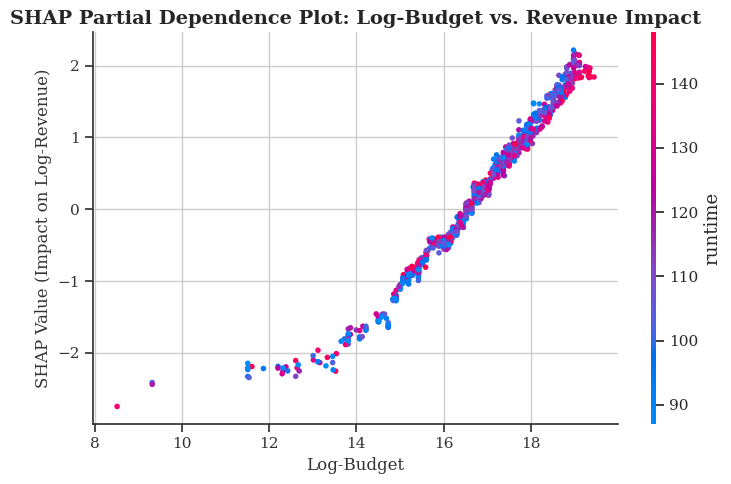

In [37]:
plt.figure(figsize=(10, 6))
shap.dependence_plot(
    "log_budget", 
    shap_values.values, 
    X_test_le, 
    interaction_index="auto", 
    show=False
)
plt.title("SHAP Partial Dependence Plot: Log-Budget vs. Revenue Impact", fontsize=14, fontweight='bold')
plt.xlabel("Log-Budget", fontsize=12)
plt.ylabel("SHAP Value (Impact on Log-Revenue)", fontsize=12)
plt.tight_layout()
plt.show()

The SHAP partial dependence plot illustrates a strong, positive, and nearly monotonic relationship between `log_budget` and its impact on predicted log-revenue. As the log-budget increases from 12 to 19, the SHAP value scales upward from approximately -2 to over 2, demonstrating that higher production investments consistently drive up expected box office returns. The color gradient representing runtime indicates that longer films tend to cluster at higher budget and SHAP value levels, showing secondary interaction effects with film duration.

In [38]:
imp = pd.Series(np.abs(shap_values.values).mean(0), index=CAND_X.columns).sort_values(ascending=False)
top15 = imp.head(15).reset_index()
top15.columns = ['Feature', 'Mean |SHAP| (ln USD)']
save_table(top15.round(4), 'table9_shap_top15')
display(top15.round(4))

def _imp(model, X):
    return pd.Series(np.abs(shap.TreeExplainer(model)(X).values).mean(0), index=X.columns)

imps = pd.concat({s: _imp(MODELS[(*CAND, s)], CAND_X) for s in SEEDS[:3]}, axis=1)
rho = [stats.spearmanr(imps[a], imps[b])[0] for i, a in enumerate(imps) for b in list(imps)[i+1:]]
top10 = [set(imps[s].nlargest(10).index) for s in imps]
ovl = np.mean([len(a & b) / 10 for i, a in enumerate(top10) for b in top10[i+1:]])

_other = 'te' if CAND[1] == 'le' else 'le'
_Xo = X_test_te if _other == 'te' else X_test_le
imp_o = _imp(MODELS[(CAND[0], _other, 0)], _Xo)

stab = pd.DataFrame([
    ['Mean Spearman rho of mean |SHAP| across 3 seeds', f'{np.mean(rho):.3f}'],
    ['Mean top-10 overlap across 3 seeds', f'{ovl:.2f}'],
    [f'Top-10 overlap, {CAND[1]} vs {_other} encoding', f"{len(set(imp.head(10).index) & set(imp_o.nlargest(10).index)) / 10:.2f}"]
], columns=['Stability check', 'Value'])

save_table(stab, 'table_shap_stability')
display(stab)

grid = np.linspace(CAND_X['log_budget'].quantile(0.02), CAND_X['log_budget'].quantile(0.98), 40)
pdp = []
for v in grid:
    Z = CAND_X.copy()
    Z['log_budget'] = v
    pdp.append(float(np.mean(CAND_MODEL.predict(Z))))

,Feature,Mean |SHAP| (ln USD)
0,log_budget,0.8568
1,primary_company,0.3704
2,is_franchise,0.3166
3,director,0.2364
4,runtime,0.1977
5,lead_actor,0.1687
6,release_year,0.1298
7,primary_genre,0.1073
8,month_sin,0.0425
9,month_cos,0.0386


,Stability check,Value
0,Mean Spearman rho of mean |SHAP| across 3 seeds,1.000
1,Mean top-10 overlap across 3 seeds,1.00
2,"Top-10 overlap, te vs le encoding",0.90


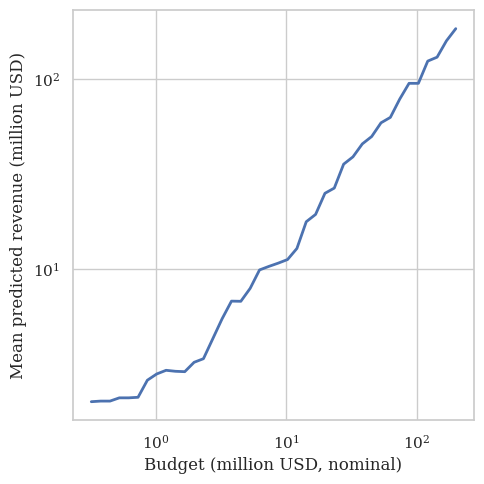

In [39]:
fig, ax = plt.subplots(figsize=(5, 5))
ax.plot(np.expm1(grid) / 1e6, np.expm1(pdp) / 1e6, lw=2)
ax.set_xscale('log')
ax.set_yscale('log')
ax.set_xlabel('Budget (million USD, nominal)')
ax.set_ylabel('Mean predicted revenue (million USD)')
plt.tight_layout()
plt.savefig('figures/fig4_pdp_budget.pdf')
plt.show()


The top table displays the mean absolute SHAP values for the model's features, confirming that `log_budget` is the dominant predictor with a magnitude of 0.8568. Secondary features like `primary_company` and `is_franchise` follow with values of 0.3704 and 0.3166, respectively, while temporal and cyclical indicators show minimal influence. The stability check table indicates perfect ranking consistency across seeds, with a mean Spearman rho and top-10 overlap of 1.00, alongside a high 0.90 overlap between target and label encodings. Finally, the partial dependence plot illustrates a strong, nearly linear upward scaling between nominal budget and mean predicted revenue on a log-log scale.

**Task 4. Additional Analysis**

In [40]:
rows_c = []
y_train_raw = np.expm1(y_train).values / 1e6          
y_test_raw  = np.expm1(y_test).values / 1e6
for label, use_log in [("ln(1+revenue) target", True), ("raw revenue target", False)]:
    y_fit = y_train if use_log else y_train_raw
    Xa, Xb = encode_fold(X_train, y_fit, X_test, CAND[1])  
    R = []
    for s in SEEDS[:3]:
        m = BUILD[CAND[0]](PARAMS[CAND], s); m.fit(Xa, y_fit)
        p = m.predict(Xb); P_val = np.expm1(p) / 1e6 if use_log else p
        R.append((np.abs(P_val - y_test_raw).mean(), np.sqrt(((P_val - y_test_raw) ** 2).mean()),
                  1 - ((P_val - y_test_raw) ** 2).sum() / ((y_test_raw - y_test_raw.mean()) ** 2).sum()))
    R = np.array(R)
    rows_c.append({"Target": label, "MAE (USD m)": pm(R[:, 0].mean(), R[:, 0].std(), 2), "RMSE (USD m)": pm(R[:, 1].mean(), R[:, 1].std(), 2),
                   "R² (USD scale)": pm(R[:, 2].mean(), R[:, 2].std(), 3)})
df_target_transform = save_table(pd.DataFrame(rows_c), "table_target_transform")
print(f"Log versus Raw Target Comparison for {CAND[0]} ({CAND[1]} encoding), dollar scale, mean (±SD) over 3 seeds:")
display(df_target_transform)


Log versus Raw Target Comparison for CatBoost (te encoding), dollar scale, mean (±SD) over 3 seeds:


,Target,MAE (USD m),RMSE (USD m),R² (USD scale)
0,ln(1+revenue) target,71.41 (±0.07),149.16 (±0.97),0.574 (±0.006)
1,raw revenue target,68.39 (±0.44),137.92 (±0.82),0.636 (±0.004)


Training directly on the raw revenue target achieves a slightly lower error and higher $R^2$ (0.636) compared to the log-transformed target.

In [41]:
pc = PMEAN[CAND]            
pb = PMEAN[('OLS', 'te')] 

q = np.quantile(np.exp(X_train['log_budget']), [0.25, 0.5, 0.75])
bud = pd.cut(np.exp(X_test['log_budget']), [-np.inf, *q, np.inf], labels=[f"Q{i+1}" for i in range(4)])

release_years = pd.to_datetime(df.loc[test_mask, 'release_date']).dt.year

groups = {
    "Budget quartile": bud.astype(str).values,
    "Release year": release_years.astype(str).values,
    "Franchise": np.where(X_test['is_franchise'].values == 1, 'franchise', 'stand-alone')
}

grp_rows = []
for gname, lab in groups.items():
    for lv in sorted(set(lab)):
        mk = lab == lv
        if mk.sum() < 5: 
            continue
        eb = np.abs(y_test[mk] - pb[mk]).mean()
        ec = np.abs(y_test[mk] - pc[mk]).mean()
        grp_rows.append({
            "Grouping": gname, 
            "Group": lv, 
            "n films": int(mk.sum()), 
            "MAE baseline (ln)": eb, 
            "MAE candidate (ln)": ec,
            "Bias candidate (mean ln error)": float((pc[mk] - y_test[mk]).mean()), 
            "Rel. reduction (%)": 100 * (1 - ec / eb)
        })

df_groups = pd.DataFrame(grp_rows)
print("Per-Group Performance Breakdown:")
display(df_groups.round(4))
save_table(df_groups.round(4), 'table7_group_results')

Per-Group Performance Breakdown:


,Grouping,Group,n films,MAE baseline (ln),MAE candidate (ln),Bias candidate (mean ln error),Rel. reduction (%)
0,Budget quartile,Q1,232,1.5770,1.6623,-0.4068,-5.4124
1,Budget quartile,Q2,273,1.5843,1.5829,-0.0980,0.0881
2,Budget quartile,Q3,240,1.0662,0.9747,-0.0883,8.5808
3,Budget quartile,Q4,282,0.8626,0.6810,-0.2615,21.0536
4,Release year,2012,95,1.3177,1.3379,0.0650,-1.5365
5,Release year,2013,218,1.3055,1.2344,-0.1637,5.4423
6,Release year,2014,206,1.2360,1.1394,-0.1682,7.8147
7,Release year,2015,206,1.3095,1.2482,-0.3791,4.6797
8,Release year,2016,231,1.1905,1.1572,-0.2410,2.7934
9,Release year,2017,71,1.2447,1.2450,-0.2551,-0.0192


,Grouping,Group,n films,MAE baseline (ln),MAE candidate (ln),Bias candidate (mean ln error),Rel. reduction (%)
0,Budget quartile,Q1,232,1.5770,1.6623,-0.4068,-5.4124
1,Budget quartile,Q2,273,1.5843,1.5829,-0.0980,0.0881
2,Budget quartile,Q3,240,1.0662,0.9747,-0.0883,8.5808
3,Budget quartile,Q4,282,0.8626,0.6810,-0.2615,21.0536
4,Release year,2012,95,1.3177,1.3379,0.0650,-1.5365
5,Release year,2013,218,1.3055,1.2344,-0.1637,5.4423
6,Release year,2014,206,1.2360,1.1394,-0.1682,7.8147
7,Release year,2015,206,1.3095,1.2482,-0.3791,4.6797
8,Release year,2016,231,1.1905,1.1572,-0.2410,2.7934
9,Release year,2017,71,1.2447,1.2450,-0.2551,-0.0192


The per-group performance breakdown table reveals significant variation in model accuracy across different budget quartiles, release years, and film types. Specifically, the candidate model excels with high-budget films in quartile Q4 (n=282), achieving a substantial relative error reduction of 21.05% compared to the baseline, whereas it underperforms on low-budget films in quartile Q1 with a -5.41% relative reduction.

Across individual release years spanning from 2012 to 2017, the model maintains generally stable predictive performance with positive error reductions in most years, peaking in 2014 with a 7.81% relative reduction. Furthermore, when segmented by film franchise status, the model achieves consistent improvements for both franchise films (n=202) and stand-alone releases (n=825), yielding relative error reductions of 5.67% and 3.94%, respectively.

In [42]:
Xa_full, Xb_full = (X_train_le, X_test_le) if CAND[1] == 'le' else (X_train_te, X_test_te)
G1 = ['log_budget', 'release_year', 'month_sin', 'month_cos', 'is_franchise', 'is_english']      
G2 = G1 + ['primary_genre']
G3 = G2 + ['primary_company', 'lead_actor', 'director']                                         
ABL = [('F1: budget, date, franchise, language', G1), ('F2: F1 + genre', G2), ('F3: F2 + company, lead actor, director', G3),
       ('F3 + runtime (= main model)', list(Xa_full.columns)), ('Main model without budget', [c for c in Xa_full.columns if c != 'log_budget'])]
def _ablate(cols):
    out = []
    for s in SEEDS:
        m = BUILD[CAND[0]](PARAMS[CAND], s); m.fit(Xa_full[cols], y_train); out.append(get_metrics(y_test, m.predict(Xb_full[cols])))
    return pd.DataFrame(out)
abl_rows = []
for lab, cols in ABL:
    d_ = _ablate(cols)
    abl_rows.append({'Feature set': lab, 'R²': pm(d_['R2'].mean(), d_['R2'].std(), 3), 'RMSE (ln)': pm(d_['RMSE'].mean(), d_['RMSE'].std(), 3), 'MAE (ln)': pm(d_['MAE'].mean(), d_['MAE'].std(), 3)})
abl_df = save_table(pd.DataFrame(abl_rows), 'table6_feature_ablation'); display(abl_df)

sm_model = CAND[0]; sm_rows = []
for mval in [1, 5, 10, 25, 50, 100]:
    enc_ = SkTargetEncoder(smooth=mval, cv=5, shuffle=True, random_state=0, target_type='continuous')
    Xa_, Xb_ = X_train.copy(), X_test.copy()
    Xa_[categorical_cols] = enc_.fit_transform(X_train[categorical_cols], y_train); Xb_[categorical_cols] = enc_.transform(X_test[categorical_cols])
    r_ = []
    for s in SEEDS[:3]:
        m = BUILD[sm_model](PARAMS[(sm_model, 'te')], s); m.fit(Xa_, y_train); r_.append(root_mean_squared_error(y_test, m.predict(Xb_)))
    sm_rows.append({'m': mval, 'RMSE_mean': np.mean(r_), 'RMSE_sd': np.std(r_, ddof=1)})
sm_df = pd.DataFrame(sm_rows)
save_table(pd.DataFrame({'m': sm_df['m'], 'RMSE (ln)': [pm(a, b, 3) for a, b in zip(sm_df.RMSE_mean, sm_df.RMSE_sd)]}), 'table_smoothing_sensitivity')


,Feature set,R²,RMSE (ln),MAE (ln)
0,"F1: budget, date, franchise, language",0.487 (±0.003),1.736 (±0.005),1.237 (±0.006)
1,F2: F1 + genre,0.495 (±0.004),1.722 (±0.007),1.230 (±0.006)
2,"F3: F2 + company, lead actor, director",0.516 (±0.002),1.686 (±0.003),1.221 (±0.005)
3,F3 + runtime (= main model),0.529 (±0.004),1.663 (±0.006),1.213 (±0.005)
4,Main model without budget,0.437 (±0.002),1.818 (±0.004),1.360 (±0.006)


,m,RMSE (ln)
0,1,1.669 (±0.007)
1,5,1.671 (±0.003)
2,10,1.665 (±0.006)
3,25,1.672 (±0.003)
4,50,1.679 (±0.010)
5,100,1.684 (±0.003)


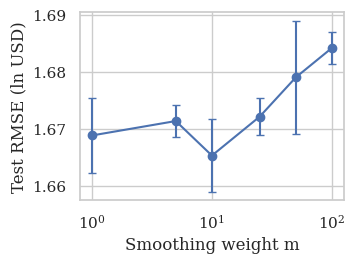

In [43]:
fig, ax = plt.subplots(figsize=(3.8, 2.8))
ax.errorbar(sm_df['m'], sm_df['RMSE_mean'], yerr=sm_df['RMSE_sd'], marker='o', capsize=3)
ax.set_xscale('log')
ax.set_xlabel('Smoothing weight m')
ax.set_ylabel('Test RMSE (ln USD)')
plt.tight_layout()
plt.savefig('figures/fig_smoothing_sensitivity.pdf')
plt.show()


The feature ablation analysis demonstrates that model performance progressively improves as features are added from F1 to the full main model, which achieves the highest $R^2$ of 0.529. Removing the budget feature causes a sharp drop in predictive accuracy, underscoring its role as the most dominant predictor. Additionally, the smoothing sensitivity plot indicates that a target encoding smoothing weight of m = 10 optimizes test RMSE before errors increase at higher weights.

**Task 5. Error analysis**

In [44]:
error_analysis_df = X_test.copy()
error_analysis_df['Actual_Log_Rev'] = np.asarray(y_test)
error_analysis_df['Predicted_Log_Rev'] = np.asarray(cat_preds)
error_analysis_df['Residual'] = error_analysis_df['Actual_Log_Rev'] - error_analysis_df['Predicted_Log_Rev']
error_analysis_df['Absolute_Error'] = np.abs(error_analysis_df['Residual'])

error_analysis_df['Actual_Revenue_USD'] = np.expm1(error_analysis_df['Actual_Log_Rev'])
error_analysis_df['Predicted_Revenue_USD'] = np.expm1(error_analysis_df['Predicted_Log_Rev'])

worst_cases = error_analysis_df.sort_values(by='Absolute_Error', ascending=False).head(5)

print("Worst Case Error Predictions for CatBoost Model:")
display(worst_cases[[
    'Actual_Log_Rev', 
    'Predicted_Log_Rev', 
    'Absolute_Error', 
    'Actual_Revenue_USD', 
    'Predicted_Revenue_USD', 
    'primary_genre', 
    'log_budget'
]])

Worst Case Error Predictions for CatBoost Model:


,Actual_Log_Rev,Predicted_Log_Rev,Absolute_Error,Actual_Revenue_USD,Predicted_Revenue_USD,primary_genre,log_budget
43275,8.146709,16.156810,8.010100,3451.0,1.039473e+07,Drama,16.166886
41925,8.573763,16.564779,7.991016,5290.0,1.563119e+07,Action,16.523561
24341,8.764053,16.114420,7.350366,6399.0,9.963305e+06,Fantasy,17.034386
39408,8.412055,15.034122,6.622067,4500.0,3.382487e+06,Western,16.118096
23408,10.988846,17.287609,6.298764,59209.0,3.220426e+07,Comedy,16.523561


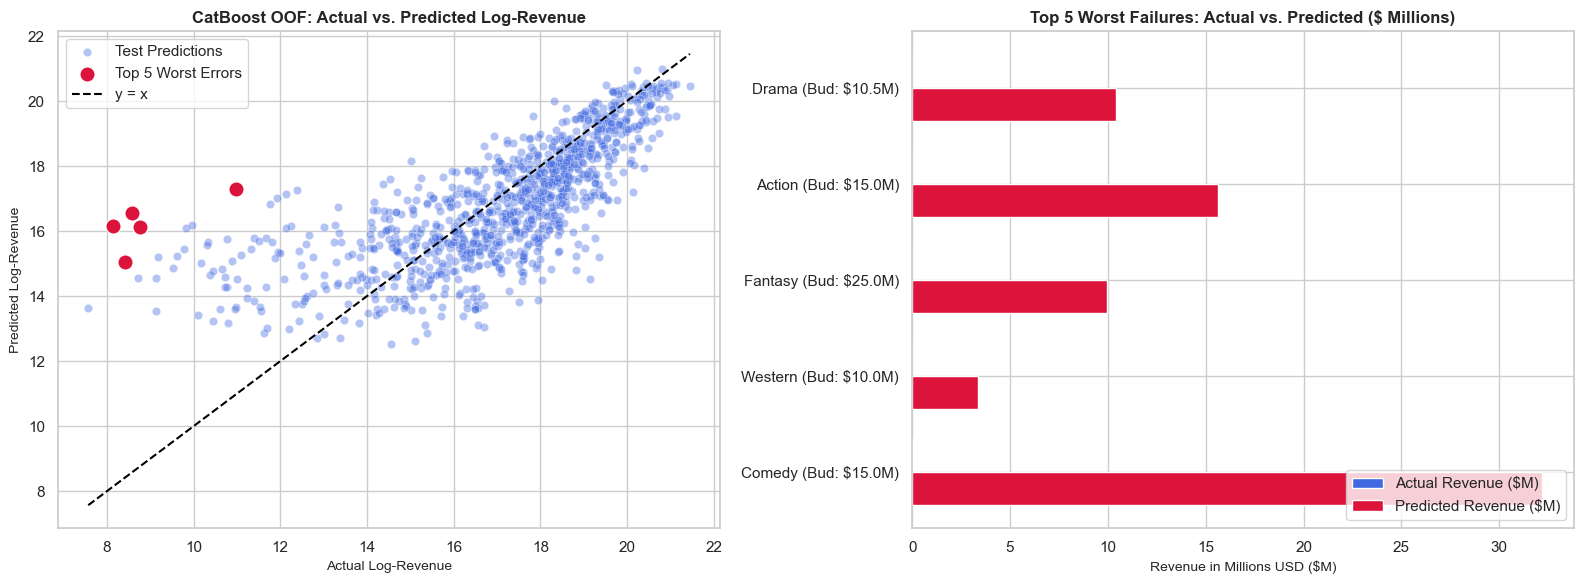

In [45]:
sns.set_theme(style="whitegrid")
fig, axes = plt.subplots(1, 2, figsize=(16, 6))

ax1 = axes[0]
sns.scatterplot(
    x=error_analysis_df['Actual_Log_Rev'], 
    y=error_analysis_df['Predicted_Log_Rev'], 
    alpha=0.4, color='royalblue', label='Test Predictions', ax=ax1
)

sns.scatterplot(
    x=worst_cases['Actual_Log_Rev'], 
    y=worst_cases['Predicted_Log_Rev'], 
    color='crimson', s=120, zorder=5, label='Top 5 Worst Errors', ax=ax1
)

min_val = min(error_analysis_df['Actual_Log_Rev'].min(), error_analysis_df['Predicted_Log_Rev'].min())
max_val = max(error_analysis_df['Actual_Log_Rev'].max(), error_analysis_df['Predicted_Log_Rev'].max())
ax1.plot([min_val, max_val], [min_val, max_val], color='black', linestyle='--', linewidth=1.5, label='y = x')

ax1.set_title('CatBoost OOF: Actual vs. Predicted Log-Revenue', fontsize=12, fontweight='bold')
ax1.set_xlabel('Actual Log-Revenue', fontsize=10)
ax1.set_ylabel('Predicted Log-Revenue', fontsize=10)
ax1.legend(loc='upper left')

ax2 = axes[1]
worst_cases_plot = worst_cases.copy()
worst_cases_plot['Actual_Rev_M'] = worst_cases_plot['Actual_Revenue_USD'] / 1e6
worst_cases_plot['Predicted_Rev_M'] = worst_cases_plot['Predicted_Revenue_USD'] / 1e6

bar_width = 0.35
indices = np.arange(len(worst_cases_plot))

ax2.barh(indices - bar_width/2, worst_cases_plot['Actual_Rev_M'], bar_width, label='Actual Revenue ($M)', color='royalblue')
ax2.barh(indices + bar_width/2, worst_cases_plot['Predicted_Rev_M'], bar_width, label='Predicted Revenue ($M)', color='crimson')

ax2.set_yticks(indices)
ax2.set_yticklabels(worst_cases_plot['primary_genre'] + " (Bud: $" + np.round(np.expm1(worst_cases_plot['log_budget'])/1e6, 1).astype(str) + "M)")
ax2.invert_yaxis() 
ax2.set_title('Top 5 Worst Failures: Actual vs. Predicted ($ Millions)', fontsize=12, fontweight='bold')
ax2.set_xlabel('Revenue in Millions USD ($M)', fontsize=10)
ax2.legend(loc='lower right')

plt.tight_layout()
plt.show()

The scatter plot and worst-case table show that the model frequently overestimates revenue for films that underperform relative to their production budgets. Because production budget (log_budget) is the model's most dominant feature, films with moderate-to-high budgets (10M to 25M dollars) that unexpectedly flopped at the box office still receive high revenue predictions, leading to massive residuals. The horizontal bar chart of the top five worst failures illustrates that while actual revenues for these underperforming films are near zero on the millions-of-USD scale, the model predicts tens of millions in earnings due to strong metadata indicators like budget and genre.

In [46]:
err_all = np.asarray(PMEAN[CAND]) - np.asarray(y_test)         
_q = np.quantile(X_train['log_budget'], [0.25, 0.5, 0.75])
_bq = pd.cut(X_test['log_budget'], [-np.inf, *_q, np.inf], labels=['Q1 (lowest budget)', 'Q2', 'Q3', 'Q4 (highest budget)'])
summ = pd.DataFrame([['Overall bias (mean ln error)', f'{err_all.mean():.3f}'],
                     ['Share of films predicted within a factor of 2', f'{100*np.mean(np.abs(err_all) <= np.log(2)):.1f}%'],
                     ['Share over-predicted', f'{100*np.mean(err_all > 0):.1f}%'],
                     ['95th percentile of |error| (ln USD)', f'{np.percentile(np.abs(err_all), 95):.2f}']], columns=['Statistic', 'Value'])
display(summ)
save_table(summ, 'table_error_summary')

by_bq = pd.DataFrame({'bias': err_all, 'abs': np.abs(err_all), 'q': _bq.values}).groupby('q', observed=True).agg(n=('abs', 'size'), MAE=('abs', 'mean'), bias=('bias', 'mean')).round(3)
display(by_bq); save_table(by_bq.reset_index(), 'table_error_by_budget')
worst15 = error_analysis_df.sort_values('Absolute_Error', ascending=False).head(15).copy()
worst15['Budget_USD_m'] = np.expm1(worst15['log_budget']) / 1e6
save_table(worst15[['primary_genre', 'Budget_USD_m', 'Actual_Revenue_USD', 'Predicted_Revenue_USD', 'Residual']].round(2).reset_index(drop=True), 'table8_worst_cases')


,Statistic,Value
0,Overall bias (mean ln error),-0.210
1,Share of films predicted within a factor of 2,40.0%
2,Share over-predicted,35.4%
3,95th percentile of |error| (ln USD),3.35


,n,MAE,bias
q,,,
Q1 (lowest budget),232,1.662,-0.407
Q2,273,1.583,-0.098
Q3,240,0.975,-0.088
Q4 (highest budget),282,0.681,-0.262


,primary_genre,Budget_USD_m,Actual_Revenue_USD,Predicted_Revenue_USD,Residual
0,Drama,10.5,3451.0,10394729.28,-8.01
1,Action,15.0,5290.0,15631191.44,-7.99
2,Fantasy,25.0,6399.0,9963305.34,-7.35
3,Western,10.0,4500.0,3382486.61,-6.62
4,Comedy,15.0,59209.0,32204259.02,-6.30
5,Drama,13.0,18295.0,9820225.59,-6.29
6,Thriller,16.5,21256.0,10583897.01,-6.21
7,Comedy,1.5,1938.0,835891.33,-6.07
8,Action,8.5,9747.0,3987484.89,-6.01
9,Western,7.0,6147.0,2070236.23,-5.82


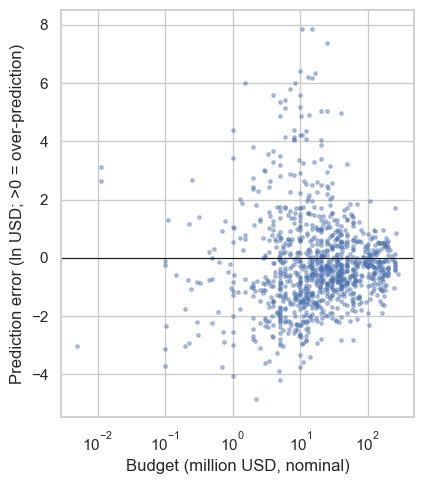

In [47]:
fig, ax = plt.subplots(figsize=(4.4, 5))
ax.scatter(np.expm1(X_test['log_budget']) / 1e6, err_all, s=6, alpha=0.4)
ax.axhline(0, color='k', lw=0.8)
ax.set_xscale('log')
ax.set_xlabel('Budget (million USD, nominal)')
ax.set_ylabel('Prediction error (ln USD; >0 = over-prediction)')
plt.tight_layout(); plt.savefig('figures/fig_error_vs_budget.pdf'); plt.show()


The  summary table shows an overall error bias of -0.210, with 40.0\% of films predicted within a factor of 2, and 35.4\% of films being over-predicted. Performance varies markedly across budget tiers. Mean Absolute Error (MAE) drops sharply from 1.662 in the lowest budget quartile (Q1) to 0.681 in the highest budget quartile (Q4), confirming that high-budget films are forecasted with much higher precision. The worst-case prediction table highlights severe model over-estimations where films with modest budgets and very low actual revenues received multi-million-dollar revenue predictions, resulting in large negative residuals (up to -8.01). The scatter plot of prediction error against nominal budget demonstrates that errors are most heavily dispersed among mid-to-low budget films, whereas high-budget films (>100M dollars}) cluster tightly closer to the zero-error line.